<a href="https://colab.research.google.com/github/Tobkubos/Systemy_AI/blob/main/SystemyAI_Lab4_Pingwiny.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Pingwiny Palmera**

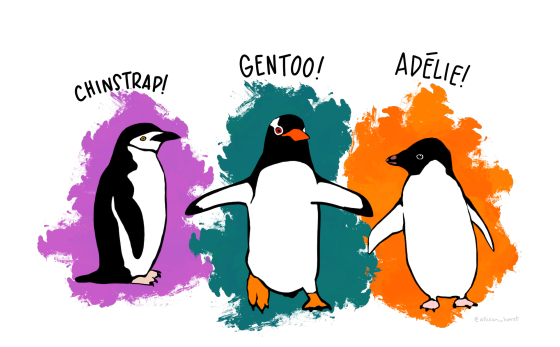

# **1. Import**

In [88]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

In [89]:
penguins = sns.load_dataset("penguins")

In [90]:
print(penguins.shape)
penguins.head()

(344, 7)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


In [91]:
penguins.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    object 
dtypes: float64(4), object(3)
memory usage: 18.9+ KB


# **2. EDA**

In [92]:
# rozkład etykiety
print(penguins["species"].value_counts(normalize=True).round(3))

# braki w procentach (tylko kolumny z brakami)
missing = penguins.isna().mean().mul(100).round(1)
missing[missing > 0]

braki = penguins[penguins.isna().any(axis=1)]
print(f"Liczba wierszy z brakami: {len(braki)}")
braki

species
Adelie       0.442
Gentoo       0.360
Chinstrap    0.198
Name: proportion, dtype: float64
Liczba wierszy z brakami: 11


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
8,Adelie,Torgersen,34.1,18.1,193.0,3475.0,NaN
9,Adelie,Torgersen,42.0,20.2,190.0,4250.0,NaN
10,Adelie,Torgersen,37.8,17.1,186.0,3300.0,NaN
11,Adelie,Torgersen,37.8,17.3,180.0,3700.0,NaN
47,Adelie,Dream,37.5,18.9,179.0,2975.0,NaN
246,Gentoo,Biscoe,44.5,14.3,216.0,4100.0,NaN
286,Gentoo,Biscoe,46.2,14.4,214.0,4650.0,NaN
324,Gentoo,Biscoe,47.3,13.8,216.0,4725.0,NaN
336,Gentoo,Biscoe,44.5,15.7,217.0,4875.0,NaN


In [93]:
# usuwanie zbędnych wierszy
print(f"Liczba wierszy przed: {len(penguins)}")

penguins = penguins.dropna(subset=["bill_length_mm"]).reset_index(drop=True)

print(f"Liczba wierszy po: {len(penguins)}")

Liczba wierszy przed: 344
Liczba wierszy po: 342


In [94]:
# skale i skośność cech liczbowych
num_cols = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
print(penguins[num_cols].describe().round(1))
print("\nskośność:", penguins[num_cols].skew().round(2).to_dict())

       bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
count           342.0          342.0              342.0        342.0
mean             43.9           17.2              200.9       4201.8
std               5.5            2.0               14.1        802.0
min              32.1           13.1              172.0       2700.0
25%              39.2           15.6              190.0       3550.0
50%              44.4           17.3              197.0       4050.0
75%              48.5           18.7              213.0       4750.0
max              59.6           21.5              231.0       6300.0

skośność: {'bill_length_mm': 0.05, 'bill_depth_mm': -0.14, 'flipper_length_mm': 0.35, 'body_mass_g': 0.47}


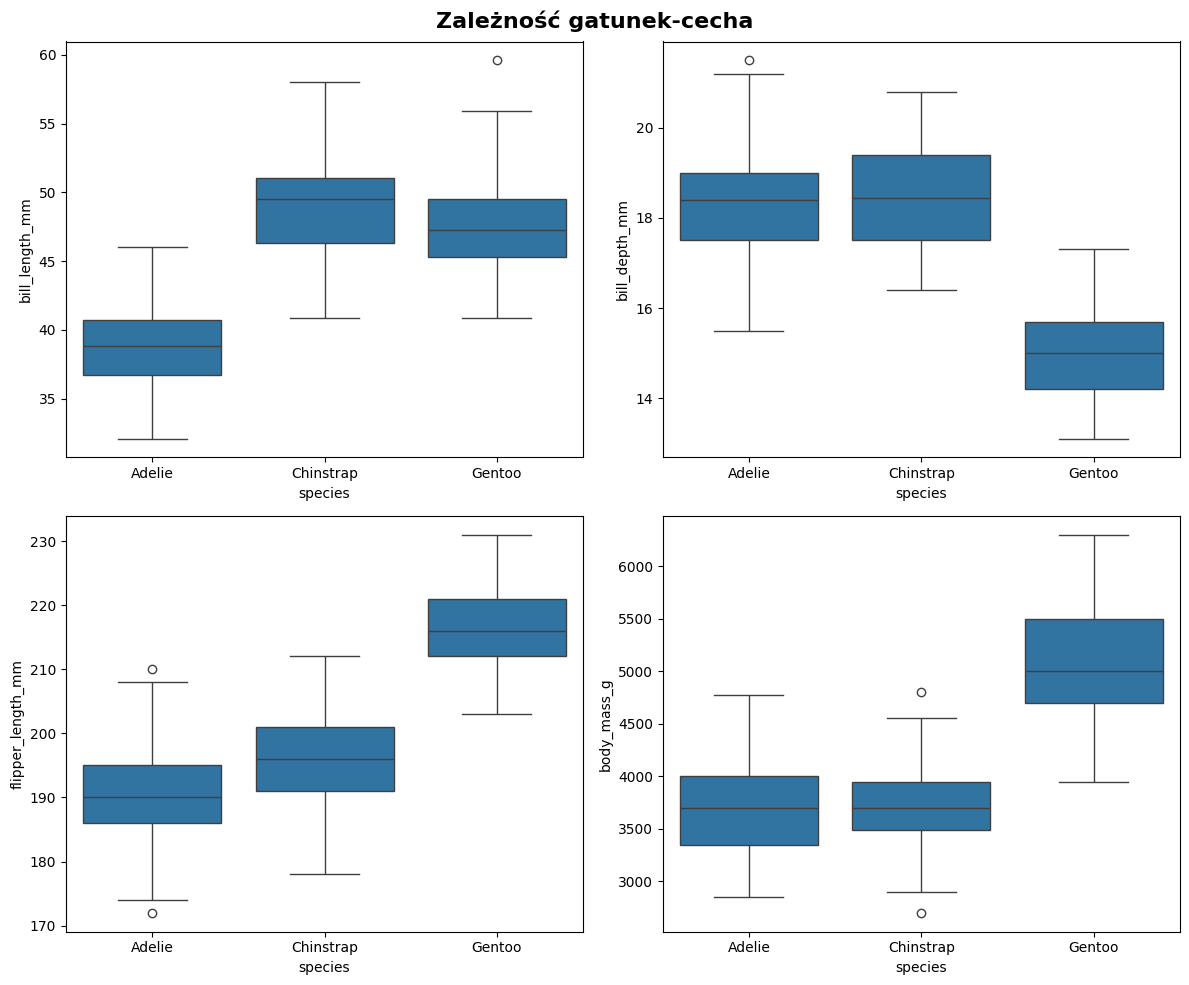

In [95]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
fig.suptitle("Zależność gatunek-cecha", fontsize=16, fontweight="bold", y=0.98)

for ax, col in zip(axes.flatten(), num_cols):
    sns.boxplot(x="species", y=col, data=penguins, ax=ax)

plt.tight_layout()
plt.show()

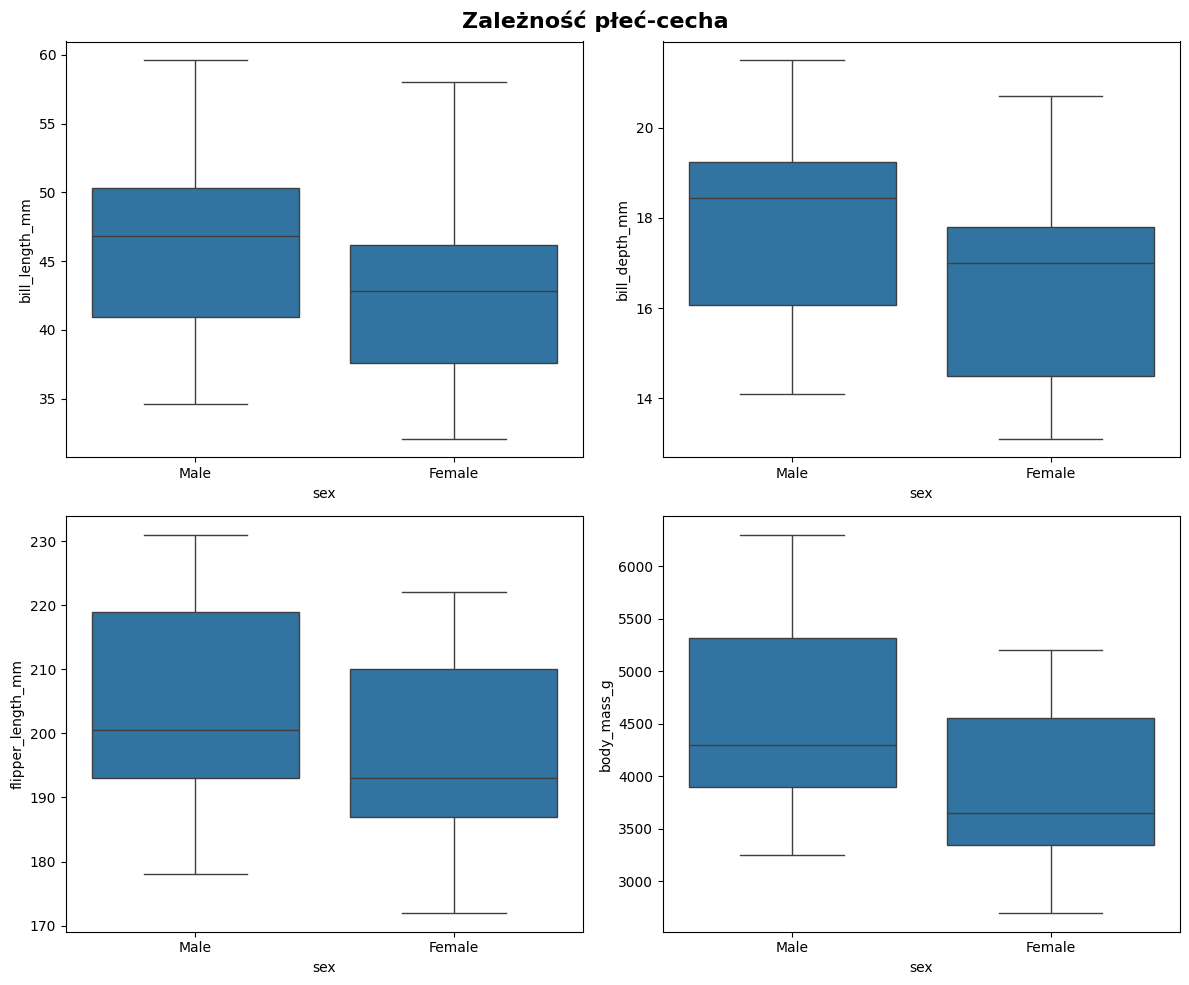

In [96]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
fig.suptitle("Zależność płeć-cecha", fontsize=16, fontweight="bold", y=0.98)

for ax, col in zip(axes.flatten(), num_cols):
    sns.boxplot(x="sex", y=col, data=penguins, ax=ax)

plt.tight_layout()
plt.show()

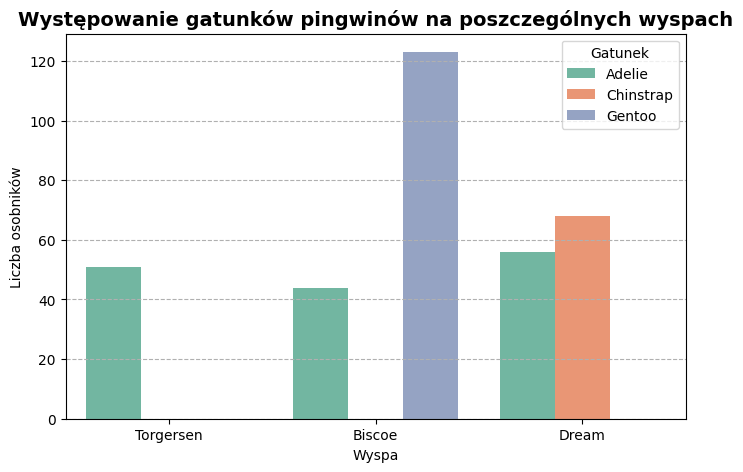

In [97]:
# Wykres gatunek - wyspa
plt.figure(figsize=(8, 5))
sns.countplot(data=penguins, x="island", hue="species", palette="Set2")

plt.title("Występowanie gatunków pingwinów na poszczególnych wyspach", fontsize=14, fontweight="bold")
plt.xlabel("Wyspa")
plt.ylabel("Liczba osobników")
plt.legend(title="Gatunek")
plt.grid(axis="y", linestyle="--")
plt.show()

### **Wnioski z EDA:**

1. **Struktura i typy danych:**
   * Zbiór danych składa się z **344 wierszy** i **7 kolumn**.
   * Mamy 4 cechy numeryczne (`bill_length_mm`, `bill_depth_mm`, `flipper_length_mm`, `body_mass_g`) oraz 3 cechy kategoryczne (`species`, `island`, `sex`).

2. **Rozkład zmiennej objaśniającej (`species`):**
   * **Adelie (44.2%)**
   * **Gentoo (36%)**
   * **Chinstrap (19.8%)**.

3. **Braki danych:**
   * Występują niewielkie braki danych dla cech numerycznych (ok. **0.6**).
   * Najwięcej braków występuje w kolumnie określającej płeć `sex` (**3.2%**).

   * 11 wierszy z brakami:
     * **2 wiersze** nie posiadają żadnego pomiaru ciała ani płci, w tym celu zostały usunięte ze zbioru.
     * **9 wierszy** posiada komplet pomiarów, brakuje im tylko wartości `sex` (3.2%), która zostanie uzupełniona wartością (`most_frequent`).


4. **Skale i skośność cech liczbowych:**
   * długość dzioba - średnio ok. 44 mm, standaryzacja.
   * masa ciała - średnio 4201.8 g, standaryzacja.
   * Skośność cech jest niewielka (wszystkie współczynniki mieszczą się w przedziale od -0.14 do 0.47) - można powiedzieć, że są symetryczne.

# **3. Podział train / test**

In [98]:
target = "species"
features = [col for col in penguins.columns if col != target]

# Podział na zbiór treningowy i testowy - stratyfikacja pozwala na taki sam odsetek gatunków w obu zbiorach
X_train, X_test, y_train, y_test = train_test_split(
    penguins[features],
    penguins[target],
    test_size=0.25,
    stratify=penguins[target],
    random_state=42
)

print("Kształt danych treningowych:", X_train.shape, y_train.shape)
print("Kształt danych testowych:", X_test.shape, y_test.shape)
print("\nRozkład klas w zbiorze treningowym (%):\n", y_train.value_counts(normalize=True).mul(100).round(1))
print("\nRozkład klas w zbiorze testowym (%):\n", y_test.value_counts(normalize=True).mul(100).round(1))

Kształt danych treningowych: (256, 6) (256,)
Kształt danych testowych: (86, 6) (86,)

Rozkład klas w zbiorze treningowym (%):
 species
Adelie       44.1
Gentoo       35.9
Chinstrap    19.9
Name: proportion, dtype: float64

Rozkład klas w zbiorze testowym (%):
 species
Adelie       44.2
Gentoo       36.0
Chinstrap    19.8
Name: proportion, dtype: float64


# **4. Przygotowanie danych: jak działa scikit-learn**

### **4a. UZUPEŁNIANIE BRAKÓW**

In [99]:
imputer = SimpleImputer(strategy="mean")
imputer.fit(X_train[["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]])

print("hiperparametr:", imputer.strategy)
print("wyuczone średnie:", imputer.statistics_)        # parametr wyuczony -> podkreślnik

penguins_test = imputer.transform(X_test[["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]])
print("braki w teście po transform:", np.isnan(penguins_test).sum())


cat_imputer = SimpleImputer(strategy="most_frequent")
cat_imputer.fit(X_train[["sex"]])

print("\n--- CECHY KATEGORYCZNE (płeć) ---")
print("hiperparametr:", cat_imputer.strategy)
print("wyuczona płeć (najczęstsza):", cat_imputer.statistics_[0])

sex_test= cat_imputer.transform(X_test[["sex"]])
print("braki w płci po transform:", pd.isna(sex_test).sum())

hiperparametr: mean
wyuczone średnie: [  44.1109375    17.1390625   201.04296875 4214.55078125]
braki w teście po transform: 0

--- CECHY KATEGORYCZNE (płeć) ---
hiperparametr: most_frequent
wyuczona płeć (najczęstsza): Male
braki w płci po transform: 0


### **4b. KODOWANIE ZMIENNYCH TEKSTOWYCH**

In [100]:
encoder = OneHotEncoder(handle_unknown="ignore")
encoder.fit(X_train[["island"]].dropna())
print("Kategorie:", encoder.categories_)

przyklad = pd.DataFrame({"island": ["Biscoe", "Dream", "Torgersen"]})
pd.DataFrame(
    encoder.transform(przyklad).toarray(),
    index=przyklad["island"],
    columns=encoder.get_feature_names_out()
)

Kategorie: [array(['Biscoe', 'Dream', 'Torgersen'], dtype=object)]


,island_Biscoe,island_Dream,island_Torgersen
island,,,
Biscoe,1.0,0.0,0.0
Dream,0.0,1.0,0.0
Torgersen,0.0,0.0,1.0


### **4c. SKALOWANIE**

In [101]:
penguins_num_train = imputer.transform(X_train[num_cols])
scaler = StandardScaler().fit(penguins_num_train)
print("średnie:", scaler.mean_.round(2))
print("odchylenia:", scaler.scale_.round(2))

penguins_num_test_s = scaler.transform(penguins_test)
print("\nPierwsze 3 wiersze zbioru testowego po skalowaniu:\n", penguins_num_test_s[:3].round(2))

średnie: [  44.11   17.14  201.04 4214.55]
odchylenia: [  5.52   2.04  13.78 792.68]

Pierwsze 3 wiersze zbioru testowego po skalowaniu:
 [[-0.38  1.16 -0.08 -0.21]
 [-0.33  1.99 -0.73 -0.08]
 [ 1.07 -0.41  2.1   1.87]]


### **4d. WSZYSTKO RAZEM**

In [102]:
num_features = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
cat_features = ["island", "sex"]

przygotowanie = ColumnTransformer([
    ("liczby", make_pipeline(SimpleImputer(strategy="mean"), StandardScaler()), num_features),
    ("kategorie", make_pipeline(SimpleImputer(strategy="most_frequent"),
                                OneHotEncoder(handle_unknown="ignore")), cat_features),
])

# Główny model w pipeline
model = make_pipeline(przygotowanie, LogisticRegression(max_iter=1000))
model

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('liczby',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer()),
                                                                  ('standardscaler',
                                                                   StandardScaler())]),
                                                  ['bill_length_mm',
                                                   'bill_depth_mm',
                                                   'flipper_length_mm',
                                                   'body_mass_g']),
                                                 ('kategorie',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehotencoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['island', 'sex'])])),
                ('logisticregression', LogisticRegression(max_iter=1000))])

# **5. TRENOWANIE**

In [103]:
model.fit(X_train, y_train)

# inspekcja: wyuczone parametry są dostępne wewnątrz pipeline'u
nazwy = model.named_steps["columntransformer"].get_feature_names_out()
wagi = pd.DataFrame(
    model.named_steps["logisticregression"].coef_,
    columns=nazwy,
    index=model.named_steps["logisticregression"].classes_
)
print("Wagi regresji logistycznej dla poszczególnych gatunków:")
wagi.round(2)

Wagi regresji logistycznej dla poszczególnych gatunków:


,liczby__bill_length_mm,liczby__bill_depth_mm,liczby__flipper_length_mm,liczby__body_mass_g,kategorie__island_Biscoe,kategorie__island_Dream,kategorie__island_Torgersen,kategorie__sex_Female,kategorie__sex_Male
Adelie,-2.24,0.98,-0.68,-0.05,0.08,-0.60,0.53,-0.57,0.57
Chinstrap,1.86,0.35,-0.27,-0.86,-0.70,1.08,-0.38,0.41,-0.40
Gentoo,0.39,-1.33,0.95,0.91,0.62,-0.48,-0.15,0.16,-0.16


# **6. PREDYKCJA**

In [104]:
y_pred = model.predict(X_test)
proba = model.predict_proba(X_test)

# Podgląd
podglad = X_test.head(5).copy()
podglad["predykcja"] = y_pred[:5]
podglad["prawda"] = y_test.head(5).values
podglad

,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,predykcja,prawda
52,Biscoe,42.0,19.5,200.0,4050.0,Male,Adelie,Adelie
48,Dream,42.3,21.2,191.0,4150.0,Male,Adelie,Adelie
220,Biscoe,50.0,16.3,230.0,5700.0,Male,Gentoo,Gentoo
316,Biscoe,46.9,14.6,222.0,4875.0,Female,Gentoo,Gentoo
92,Dream,39.6,18.1,186.0,4450.0,Male,Adelie,Adelie


# **7. EWALUACJA**

In [105]:
baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)

wyniki = pd.Series({
    "baseline (najczęstszy gatunek)": baseline.score(X_test, y_test),
    "pipeline – train": model.score(X_train, y_train),
    "pipeline – test": model.score(X_test, y_test),
})
print("Porównanie wyników dokładności (accuracy):\n", wyniki.round(3), "\n")



Porównanie wyników dokładności (accuracy):
 baseline (najczęstszy gatunek)    0.442
pipeline – train                  0.996
pipeline – test                   1.000
dtype: float64 



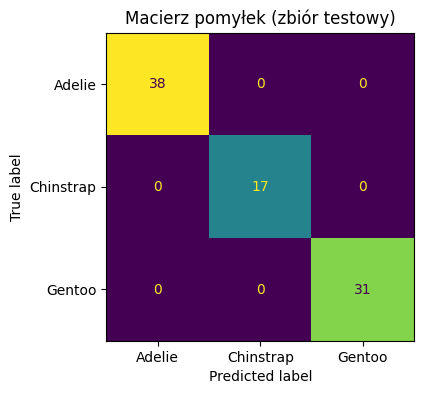

              precision    recall  f1-score   support

      Adelie      1.000     1.000     1.000        38
   Chinstrap      1.000     1.000     1.000        17
      Gentoo      1.000     1.000     1.000        31

    accuracy                          1.000        86
   macro avg      1.000     1.000     1.000        86
weighted avg      1.000     1.000     1.000        86



In [106]:
fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=model.classes_).plot(ax=ax, colorbar=False)
ax.set_title("Macierz pomyłek (zbiór testowy)")
plt.show()

print(classification_report(y_test, y_pred, digits=3))

# **8. ITERACJA**

In [108]:
def zbuduj(num, cat, strategy="mean"):
    przyg = ColumnTransformer([
        ("liczby", make_pipeline(SimpleImputer(strategy=strategy), StandardScaler()), num),
        ("kategorie", make_pipeline(SimpleImputer(strategy="most_frequent"), OneHotEncoder(handle_unknown="ignore")), cat),
    ])
    return make_pipeline(przyg, LogisticRegression(max_iter=1000))

# Testowane:
# 1. Pełny model: imputacja średnia
# 2. Imputacja medianą zamiast średniej
# 3. Model bez'island'
warianty = {
    "pełny (średnia)": zbuduj(num_features, cat_features, strategy="mean"),
    "imputacja medianą": zbuduj(num_features, cat_features, strategy="median"),
    "bez parametru wyspy": zbuduj(num_features, ["sex"]),
}

pd.Series({nazwa: m.fit(X_train, y_train).score(X_test, y_test) for nazwa, m in warianty.items()}).round(3)

,0
pełny (średnia),1.0
imputacja medianą,1.0
bez parametru wyspy,1.0


1. **Imputacja średnią vs medianą:**
   * Obie strategie dają identyczny wynik. Wynika to z tego, że średnia i mediana leżą bardzo blisko siebie.

2. **Wariant bez cechy 'island':**
   * Usunięcie informacji o wyspie nie obniża jakości predykcji, ponieważ model nadal uzyskuje 100% accuracy.
   * Same cechy anatomiczne ptaka są w zupełności wystarczające do bezbłędnego zidentyfikowania gatunku pingwina.